# 07 · Summary

All runs from notebooks 00–06 in one place. Every run used the same 5 × 10-fold stratified CV
(seeds 0–4), so differences between runs are **paired**: for each repeat we can subtract the old
model's score from the new model's score on exactly the same 114 out-of-fold predictions.

In [1]:
import glob
import os
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cofreg import plots
from cofreg.cv import load_oof, pooled_scores
from cofreg.data import RESULTS_DIR, load_data

plots.style()
y = load_data().capacity_max.to_numpy()
COLS = ["experiment", "model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean"]
runs = pd.concat([pd.read_csv(p) for p in sorted(glob.glob(os.path.join(RESULTS_DIR, "*", "summary.csv")))], ignore_index=True)
print(f"{len(runs)} runs in {runs.experiment.nunique()} experiments")

91 runs in 7 experiments


## Best runs by each metric

In [2]:
best = {
    "pairwise accuracy": runs.sort_values("pa_mean", ascending=False).head(8),
    "MALE": runs.sort_values("male_mean").head(8),
    "RMSE": runs.sort_values("rmse_mean").head(8),
}
for title, df in best.items():
    print(f"--- top by {title}")
    print(df[COLS].round(3).to_string(index=False))

--- top by pairwise accuracy
         experiment                                             model  mape_mean  pa_mean  pa_std  rmse_mean  male_mean  mape_ge20_mean  r2_mean
        02_features rf_log | descriptor+ecfp+estate+fg (old BRR best)      1.580    0.685   0.008    187.248      0.692           0.606    0.084
     04_tree_models                          rf | desc+ecfp+estate+fg      1.580    0.685   0.008    187.248      0.692           0.606    0.084
     04_tree_models                  rf_innercv | desc+ecfp+estate+fg      1.576    0.684   0.007    186.290      0.694           0.600    0.094
     04_tree_models                     xgboost | desc+ecfp+estate+fg      1.505    0.682   0.013    192.020      0.692           0.631    0.037
        02_features                      catboost_log | morgan2 (own)      1.774    0.682   0.007    185.480      0.713           0.680    0.101
        06_ensemble                           ensemble_rf_catboost_gp      1.437    0.681   0.008    

## Old best models vs the new candidates

The final shortlist: the two old best models (rerun in notebook 00) and the best model of each new family.

In [3]:
SHORTLIST = {
    "old BRR (old protocol)": ("00_baseline", "old_brr"),
    "old RF (old protocol)": ("00_baseline", "old_rf"),
    "RF, log target (estate+fg)": ("04_tree_models", "rf | estate+fg"),
    "RF, log target, inner-CV tuned (estate+fg)": ("04_tree_models", "rf_innercv | estate+fg"),
    "RF, log target (desc+ecfp+estate+fg)": ("04_tree_models", "rf | desc+ecfp+estate+fg"),
    "CatBoost, log target (desc+ecfp+estate+fg)": ("04_tree_models", "catboost | desc+ecfp+estate+fg"),
    "GP Tanimoto+RBF, log target": ("03_bayesian_models", "gp_tanimoto+rbf | ecfp+descriptor"),
    "TabPFN, log target (rdkit+redox)": ("05_pretrained", "tabpfn | rdkit+redox"),
    "CheMeleon fine-tuned, log target": ("05_pretrained", "chemeleon_finetune"),
    "Ensemble RF + CatBoost + GP": ("06_ensemble", "ensemble_rf_catboost_gp"),
}
scores = {label: pooled_scores(y, load_oof(*key)[1]) for label, key in SHORTLIST.items()}
final = pd.DataFrame(
    [{"model": label} | {f"{m}_mean": s[m].mean() for m in s} | {f"{m}_std": s[m].std(ddof=1) for m in s} for label, s in scores.items()]
)
final[["model", "mape_mean", "pa_mean", "pa_std", "rmse_mean", "male_mean", "mape_ge20_mean", "r2_mean"]].round(3)

,model,mape_mean,pa_mean,pa_std,rmse_mean,male_mean,mape_ge20_mean,r2_mean
0,old BRR (old protocol),3.655,0.666,0.009,177.788,0.786,0.850,0.174
1,old RF (old protocol),2.687,0.652,0.011,182.374,0.754,0.890,0.131
2,"RF, log target (estate+fg)",1.397,0.677,0.008,187.035,0.688,0.606,0.086
3,"RF, log target, inner-CV tuned (estate+fg)",1.402,0.679,0.011,180.489,0.679,0.618,0.149
4,"RF, log target (desc+ecfp+estate+fg)",1.580,0.685,0.008,187.248,0.692,0.606,0.084
5,"CatBoost, log target (desc+ecfp+estate+fg)",1.497,0.677,0.012,191.340,0.689,0.634,0.044
6,"GP Tanimoto+RBF, log target",1.577,0.663,0.007,194.219,0.704,0.667,0.015
7,"TabPFN, log target (rdkit+redox)",1.652,0.677,0.007,183.113,0.678,0.670,0.124
8,"CheMeleon fine-tuned, log target",3.631,0.614,0.010,225.818,0.937,0.904,-0.333
9,Ensemble RF + CatBoost + GP,1.437,0.681,0.008,188.665,0.673,0.610,0.070


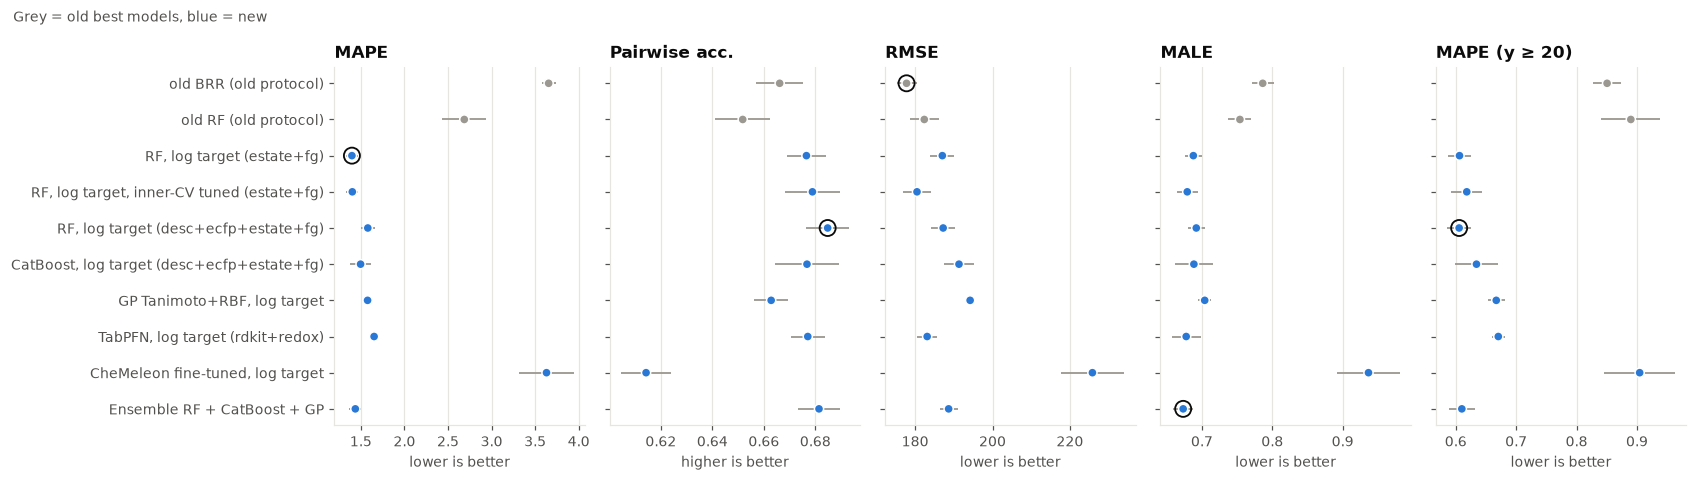

In [4]:
fig = plots.metric_dots(final, metrics=("mape", "pa", "rmse", "male", "mape_ge20"), highlight={k: plots.GRAY for k in SHORTLIST if k.startswith("old")})
fig.suptitle("Grey = old best models, blue = new", x=0.01, ha="left", fontsize=9, color=plots.INK_2)
fig.tight_layout()

## Paired improvement over the old models

For each repeat: new score − old score on the same folds, then mean ± std over the 5 repeats.
Signs are flipped where lower is better, so **positive = the new model is better** in every panel.

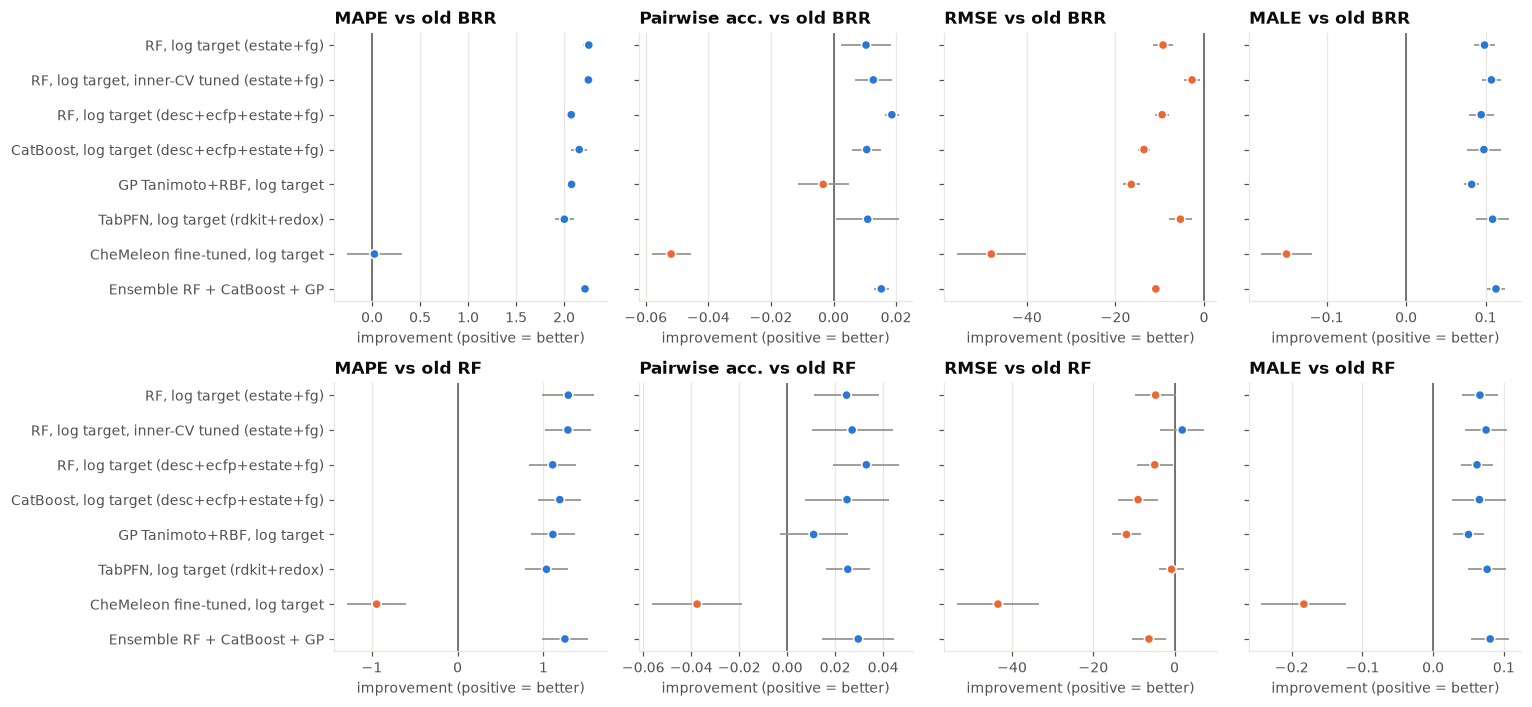

In [5]:
SIGN = {"mape": -1, "pa": 1, "rmse": -1, "male": -1}
new_models = [k for k in SHORTLIST if not k.startswith("old")]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey=True)
for row, ref in zip(axes, ["old BRR (old protocol)", "old RF (old protocol)"]):
    for ax, m in zip(row, SIGN):
        deltas = np.array([SIGN[m] * (scores[n][m] - scores[ref][m]).to_numpy() for n in new_models])
        ypos = np.arange(len(new_models))[::-1]
        ax.axvline(0, color=plots.INK_2, linewidth=1)
        ax.errorbar(deltas.mean(1), ypos, xerr=deltas.std(1, ddof=1), fmt="none", ecolor=plots.GRAY, elinewidth=1.2)
        colors = [plots.BLUE if v > 0 else plots.ORANGE for v in deltas.mean(1)]
        ax.scatter(deltas.mean(1), ypos, c=colors, s=36, edgecolors="white", linewidths=1, zorder=3)
        ax.set_yticks(ypos, new_models)
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{plots.LABELS[m]} vs {ref.split(' (')[0]}", loc="left")
        ax.set_xlabel("improvement (positive = better)")
fig.tight_layout()

## Conclusions

**What was tried** (91 runs, all on the same 5 × 10-fold CV): the old best BRR/RF/XGBoost with the old
protocol (00); raw, sqrt, log and rank targets (01); 16 feature sets including new redox /
theoretical-capacity features and all RDKit descriptors (02); Bayesian ridge, ARD, Gaussian processes
with RBF and Tanimoto kernels, kernel ridge, SVR (03); RF, ExtraTrees, XGBoost, LightGBM, CatBoost with
fixed, old-protocol and nested inner-CV tuning (04); frozen and fine-tuned CheMeleon, TabPFN (05);
ensembles (06).

**What beats the old models.** Paired over the 5 repeats, random forest with a **log target** on
EState + functional groups, compared with the old RF:

| | old RF | new RF (log) | paired change |
|---|---|---|---|
| MAPE | 2.69 | 1.40 | −1.29 ± 0.30 |
| pairwise accuracy | 0.652 | 0.677 | +0.025 ± 0.013 (better in 5/5 repeats) |
| MALE | 0.754 | 0.688 | −0.066 ± 0.025 |
| RMSE | 182.4 | 187.0 | +4.7 ± 5.1 (about the same) |

Against the old BRR the new RF has MAPE −2.26, PA +0.010 (5/5 repeats), but RMSE +9 (worse).
Inner-CV tuning of the same RF brings RMSE back to 180.5 (−1.9 vs old RF) with the same other gains.

**Recommendations**
- Use the **log target** by default: it is the single change that matters (MAPE roughly halved).
- Model: **random forest** (log target, EState + functional groups, `min_samples_leaf=2`,
  `max_features=0.3`, 500 trees). Use the descriptors + ECFP + EState + fg set if ranking matters most
  (PA 0.685). The RF + CatBoost + GP ensemble is a small further gain (MALE 0.673).
- **Don't optimise MAPE alone**: predicting a constant 6 gives MAPE 0.94, better than any model.
  Report pairwise accuracy, RMSE and MALE (or MAPE on y ≥ 20) next to it.
- Tuning, pretrained models (CheMeleon, TabPFN) and extra features didn't give real gains on 114
  substrates; don't spend more time there without more data.

**Why the ceiling is low.** Every reasonable model ends at PA ≈ 0.68 and R² ≈ 0.1. Even the most
similar substrate in the dataset predicts capacity poorly (Spearman 0.36), so a lot of the variance
is probably not in the monomer structure (COF partner, electrode preparation, test conditions).
The most promising next steps are more data, or features describing the COF and the measurement,
and the main/side chain split (task 1) as a structural representation to test with this same protocol.